# Lab 14 — Data Poisoning Robustness

*AI Cybersecurity Masterclass · Lab 14 · AI60secLab*

**Companion video:** [▶ How Attackers Poison AI Training Data](https://www.youtube.com/watch?v=IOadMjp3aCU&list=PLG4l6Ssi9A00)

**Research question:** How quickly does detection performance degrade when a small fraction of training data is corrupted?

We study two controlled offline conditions:
1. random binary label flips;
2. bounded numeric feature corruption.

Protocol rules:
- the original data is never modified; only a **copy** of the training data is corrupted;
- every corruption level trains a **new model**, because the training data changed;
- the clean held-out test set stays exactly the same;
- every level is repeated with **several random seeds**, and an effect only counts if it is larger than the spread between seeds.

## Security foundation: data integrity and supply chains

Integrity attacks target what systems *learn from* or *trust*, rather than the system itself:
- **software supply chain:** compromise a library or update, and every user installs the attack;
- **data supply chain:** corrupt the logs, labels, or threat feeds a model learns from;
- **feedback loops:** if analysts' dismissals become training labels, an attacker who gets alerts dismissed teaches the model to ignore them;
- **insiders:** someone with legitimate access changes labels or data.

The defenses are the same idea at every level: know where data came from (**provenance**), restrict who can change it, validate before use, and keep a known-good version to return to.

In [ ]:
# Setup: works in Google Colab and locally. No uploads needed.
# In Colab this clones the course repo, which already includes the UNSW-NB15 data.
from pathlib import Path
import sys, os

REPO_URL = "https://github.com/Jacquelinepersha/ai-cybersecurity-public-labs.git"
REPO_NAME = "ai-cybersecurity-public-labs"

try:
    import google.colab  # noqa: F401
    if not Path(REPO_NAME).exists():
        !git clone --depth 1 {REPO_URL}
    os.chdir(REPO_NAME)
except ImportError:
    pass

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data folder :", DATA_DIR)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import load_unsw
from src.preprocessing import split_xy, align_columns
from src.features import drop_identifier_like_columns
from src.models import logistic_pipeline
from src.evaluation import binary_metrics
from src.poisoning import (
    random_label_flip,
    corrupt_numeric_training_rows,
    poisoning_summary,
)
from src.robustness import feature_bounds

train, test = load_unsw(DATA_DIR)

X_train, y_train = split_xy(train, "label")
X_test, y_test = split_xy(test, "label")
X_train, X_test = align_columns(X_train, X_test)

X_train = drop_identifier_like_columns(X_train)
X_test = drop_identifier_like_columns(X_test)

In [3]:
SEEDS = [0, 1, 2]
FRACTIONS = [0.00, 0.01, 0.03, 0.05, 0.10]

label_rows = []

for fraction in FRACTIONS:
    for seed in SEEDS:
        poisoned_y = random_label_flip(
            y_train,
            fraction=fraction,
            random_state=seed,
        )

        model = logistic_pipeline(X_train)
        model.fit(X_train, poisoned_y)

        pred = model.predict(X_test)
        score = model.predict_proba(X_test)[:, 1]
        metrics = binary_metrics(y_test, pred, score)
        summary = poisoning_summary(y_train, poisoned_y)

        label_rows.append({
            "fraction": fraction,
            "seed": seed,
            "actual_changed_fraction": summary["changed_fraction"],
            "precision": metrics.precision,
            "recall": metrics.recall,
            "f1": metrics.f1,
            "false_negative_rate": metrics.false_negative_rate,
        })

label_runs = pd.DataFrame(label_rows)
label_results = (
    label_runs.groupby("fraction")[["recall", "f1", "false_negative_rate"]]
    .agg(["mean", "std"])
)
display(label_results.round(4))

recall              f1         false_negative_rate        
            mean     std    mean     std                mean     std
fraction                                                            
0.00      0.9302  0.0000  0.8619  0.0000              0.0698  0.0000
0.01      0.9347  0.0011  0.8560  0.0008              0.0653  0.0011
0.03      0.9463  0.0016  0.8559  0.0008              0.0537  0.0016
0.05      0.9534  0.0017  0.8561  0.0007              0.0466  0.0017
0.10      0.9647  0.0022  0.8565  0.0009              0.0353  0.0022

In [4]:
numeric_columns = [
    c for c in [
        "dur", "sbytes", "dbytes", "spkts",
        "dpkts", "rate", "sload", "dload"
    ]
    if c in X_train.columns
]

bounds = feature_bounds(X_train, numeric_columns)
feature_rows = []

for fraction in FRACTIONS:
    for seed in SEEDS:
        poisoned_X = corrupt_numeric_training_rows(
            X_train,
            fraction=fraction,
            columns=numeric_columns,
            noise_fraction=0.30,
            bounds=bounds,
            random_state=seed,
        )

        model = logistic_pipeline(poisoned_X)
        model.fit(poisoned_X, y_train)

        pred = model.predict(X_test)
        score = model.predict_proba(X_test)[:, 1]
        metrics = binary_metrics(y_test, pred, score)

        feature_rows.append({
            "fraction": fraction,
            "seed": seed,
            "precision": metrics.precision,
            "recall": metrics.recall,
            "f1": metrics.f1,
            "false_negative_rate": metrics.false_negative_rate,
        })

feature_runs = pd.DataFrame(feature_rows)
feature_results = (
    feature_runs.groupby("fraction")[["recall", "f1", "false_negative_rate"]]
    .agg(["mean", "std"])
)
display(feature_results.round(4))

recall              f1         false_negative_rate        
            mean     std    mean     std                mean     std
fraction                                                            
0.00      0.9302  0.0000  0.8619  0.0000              0.0698  0.0000
0.01      0.9310  0.0005  0.8619  0.0003              0.0690  0.0005
0.03      0.9314  0.0009  0.8620  0.0006              0.0686  0.0009
0.05      0.9312  0.0003  0.8619  0.0001              0.0688  0.0003
0.10      0.9309  0.0002  0.8616  0.0003              0.0691  0.0002

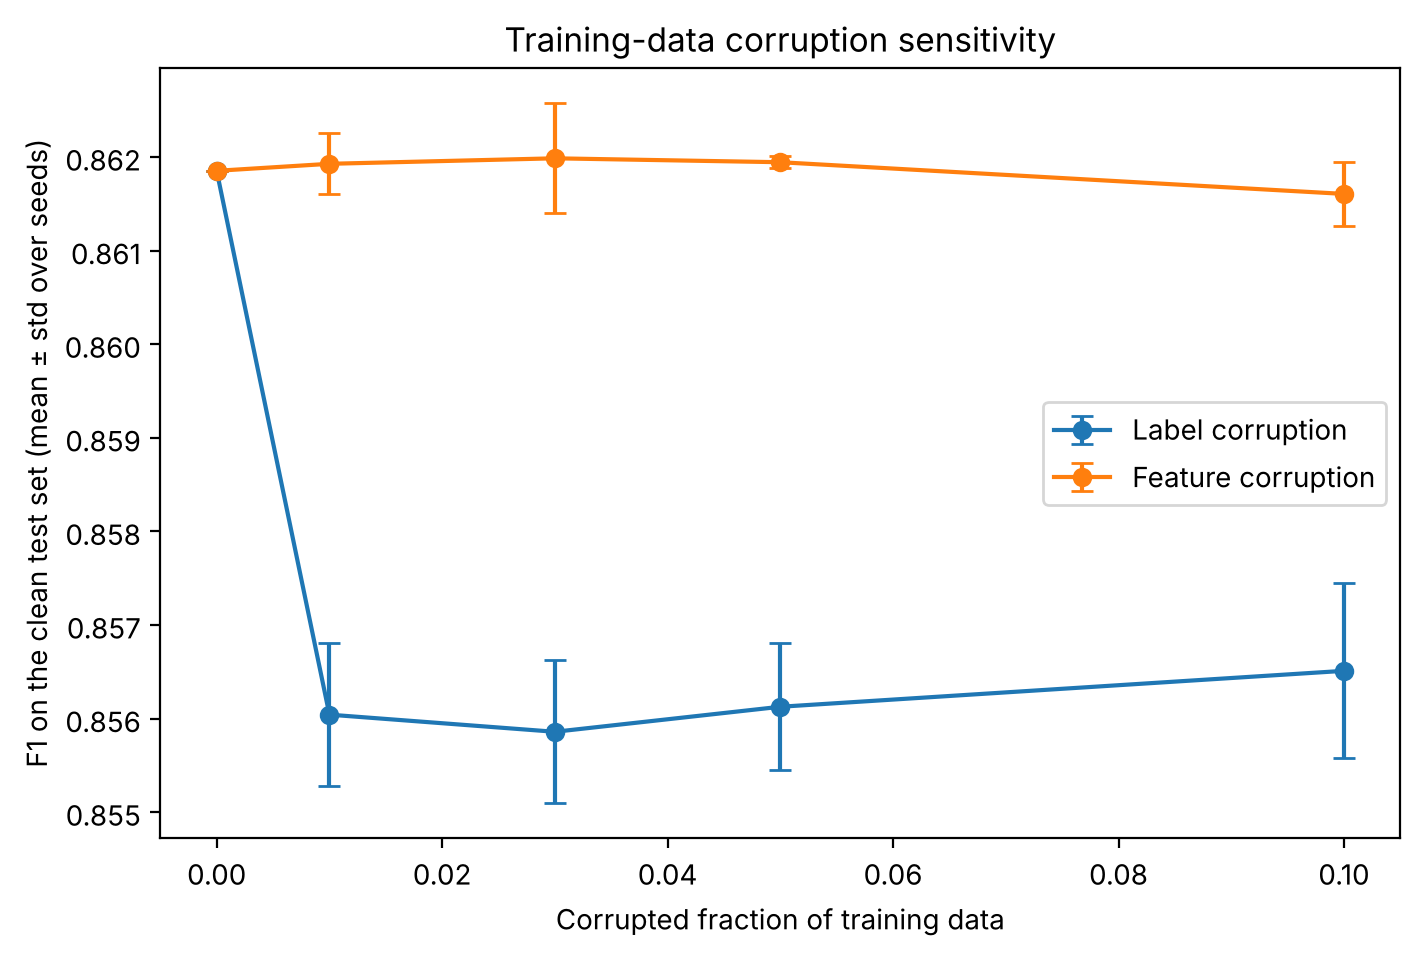

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, runs in [("Label corruption", label_runs), ("Feature corruption", feature_runs)]:
    stats = runs.groupby("fraction")["f1"].agg(["mean", "std"]).reset_index()
    ax.errorbar(stats["fraction"], stats["mean"], yerr=stats["std"], marker="o", capsize=4, label=label)
ax.set_xlabel("Corrupted fraction of training data")
ax.set_ylabel("F1 on the clean test set (mean ± std over seeds)")
ax.set_title("Training-data corruption sensitivity")
ax.legend()
plt.show()

## Step 4: Does the effect beat the noise?

A drop only counts if it is larger than the spread between seeds. Compare each corruption level with the clean baseline.

In [6]:
def effect_table(runs, metric="f1"):
    stats = runs.groupby("fraction")[metric].agg(["mean", "std"])
    clean_mean = stats.loc[0.0, "mean"]
    noise = stats["std"].max()
    out = stats.assign(
        delta_vs_clean=stats["mean"] - clean_mean,
        exceeds_seed_spread=lambda d: (d["delta_vs_clean"].abs() > 2 * noise),
    )
    return out

print("Label corruption, F1:")
display(effect_table(label_runs).round(4))
print("Feature corruption, F1:")
display(effect_table(feature_runs).round(4))

Label corruption, F1:


,mean,std,delta_vs_clean,exceeds_seed_spread
fraction,,,,
0.00,0.8619,0.0000,0.0000,False
0.01,0.8560,0.0008,-0.0058,True
0.03,0.8559,0.0008,-0.0060,True
0.05,0.8561,0.0007,-0.0057,True
0.10,0.8565,0.0009,-0.0053,True


Feature corruption, F1:


,mean,std,delta_vs_clean,exceeds_seed_spread
fraction,,,,
0.00,0.8619,0.0000,0.0000,False
0.01,0.8619,0.0003,0.0001,False
0.03,0.8620,0.0006,0.0001,False
0.05,0.8619,0.0001,0.0001,False
0.10,0.8616,0.0003,-0.0002,False


## Interpretation

- Which corruption type damaged performance faster?
- Which deltas exceed the seed spread, and which could be noise?
- If small corruption causes large degradation, training-data integrity is a security risk. Is that what you see here?
- How would provenance checks, validation rules, and trusted training pipelines reduce poisoning risk?

**Takeaway:** training data is part of the ML system's security boundary. The model is only as trustworthy as the learning process.

## From lab to SOC

Training pipelines are production systems and need the same controls: access control, change logs, and validation gates. In this lab, 1% to 10% label flips cost little F1, but targeted poisoning (Lab 28) can blind a detector to one attack type while the dashboard looks fine.

**Check yourself**
1. Describe how an attacker could poison a detector that retrains on analyst feedback.
2. What is the data-pipeline equivalent of signing a software update?
3. Why is targeted poisoning more dangerous than random label noise?